In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

CORE = ["tensile_strength_MPa", "yield_strength_MPa", "elongation_pct",
        "youngs_modulus_GPa", "density_g_cm3"]

df = pd.read_csv("../data/processed/materials_clean.csv")
print(df.shape)
df["family"].value_counts()

(1256, 18)


family
Steel              684
Aluminium          197
Copper alloy       166
Stainless steel    117
Cast iron           62
Magnesium           30
Name: count, dtype: int64

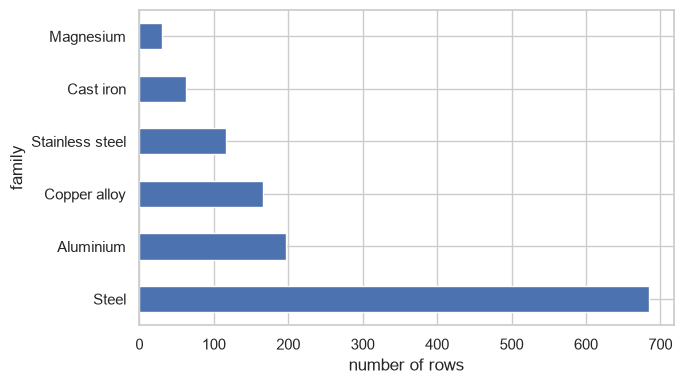

family
Steel              54.5
Aluminium          15.7
Copper alloy       13.2
Stainless steel     9.3
Cast iron           4.9
Magnesium           2.4
Name: count, dtype: float64


In [3]:
counts = df["family"].value_counts()
counts.plot.barh(figsize=(7, 4))
plt.xlabel("number of rows"); plt.tight_layout()
plt.savefig("../figures/03_family_counts.png", dpi=150); plt.show()
print((counts / len(df) * 100).round(1))

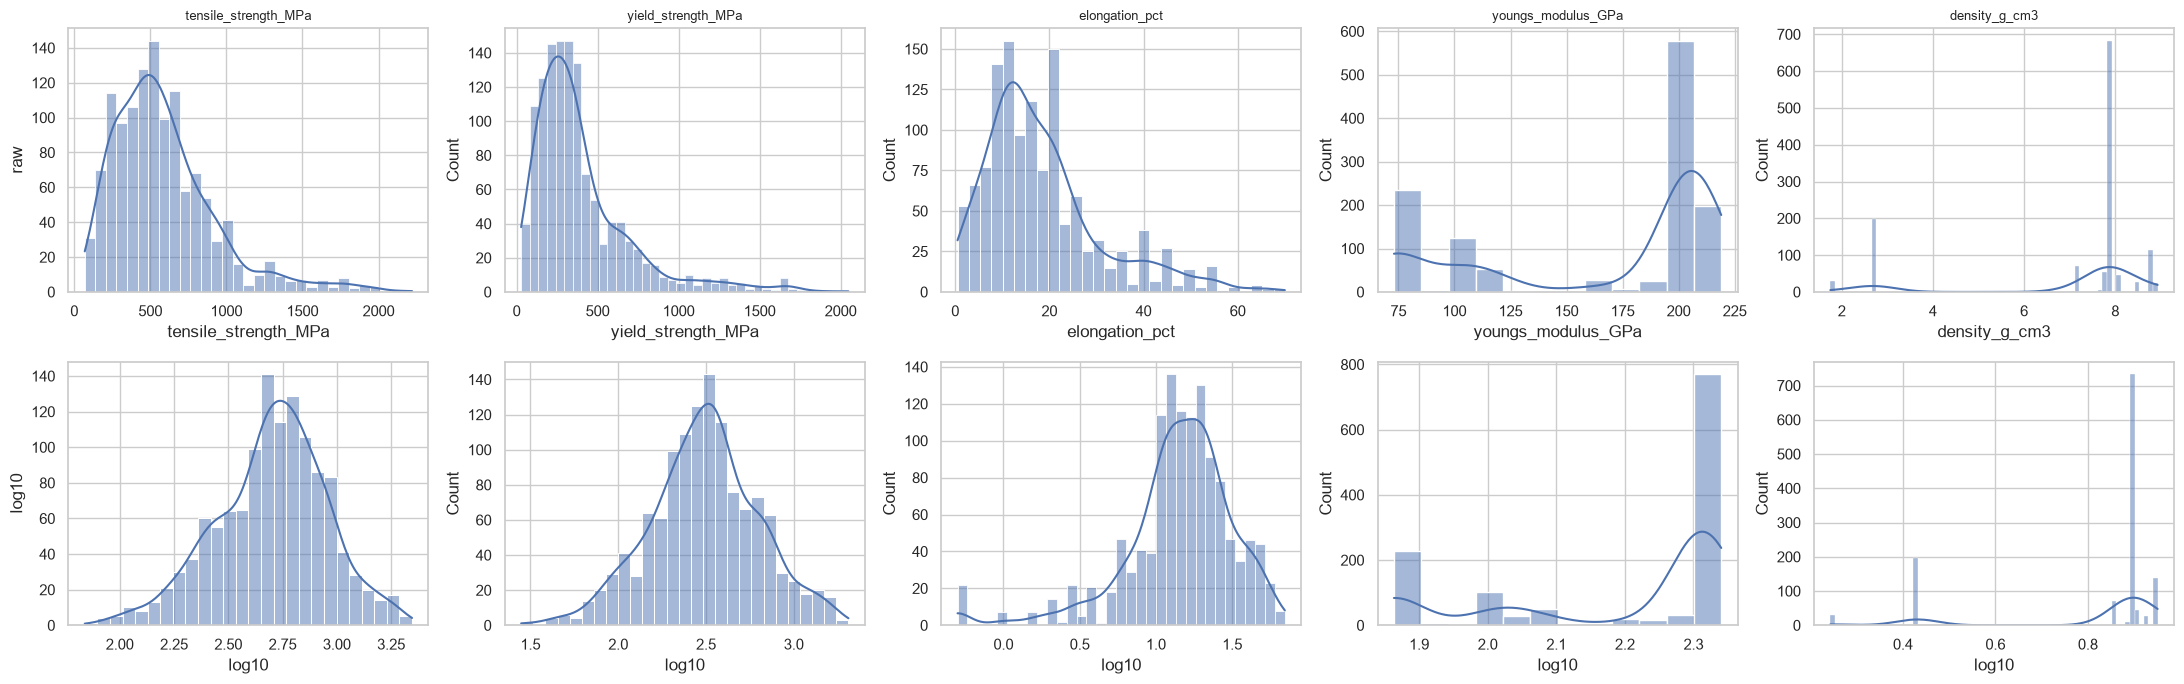

Skewness raw:
 tensile_strength_MPa    1.43
yield_strength_MPa      2.00
elongation_pct          1.30
youngs_modulus_GPa     -0.77
density_g_cm3          -1.56
dtype: float64

Skewness log10:
 tensile_strength_MPa   -0.32
yield_strength_MPa     -0.10
elongation_pct         -1.38
youngs_modulus_GPa     -0.90
density_g_cm3          -1.71
dtype: float64


In [4]:
fig, axes = plt.subplots(2, 5, figsize=(22, 7))
for i, c in enumerate(CORE):
    sns.histplot(df[c], kde=True, ax=axes[0, i]); axes[0, i].set_title(c, fontsize=9)
    sns.histplot(np.log10(df[c]), kde=True, ax=axes[1, i]); axes[1, i].set_xlabel("log10")
axes[0, 0].set_ylabel("raw"); axes[1, 0].set_ylabel("log10")
plt.tight_layout(); plt.savefig("../figures/03_distributions.png", dpi=150); plt.show()

print("Skewness raw:\n", df[CORE].skew().round(2))
print("\nSkewness log10:\n", np.log10(df[CORE]).skew().round(2))

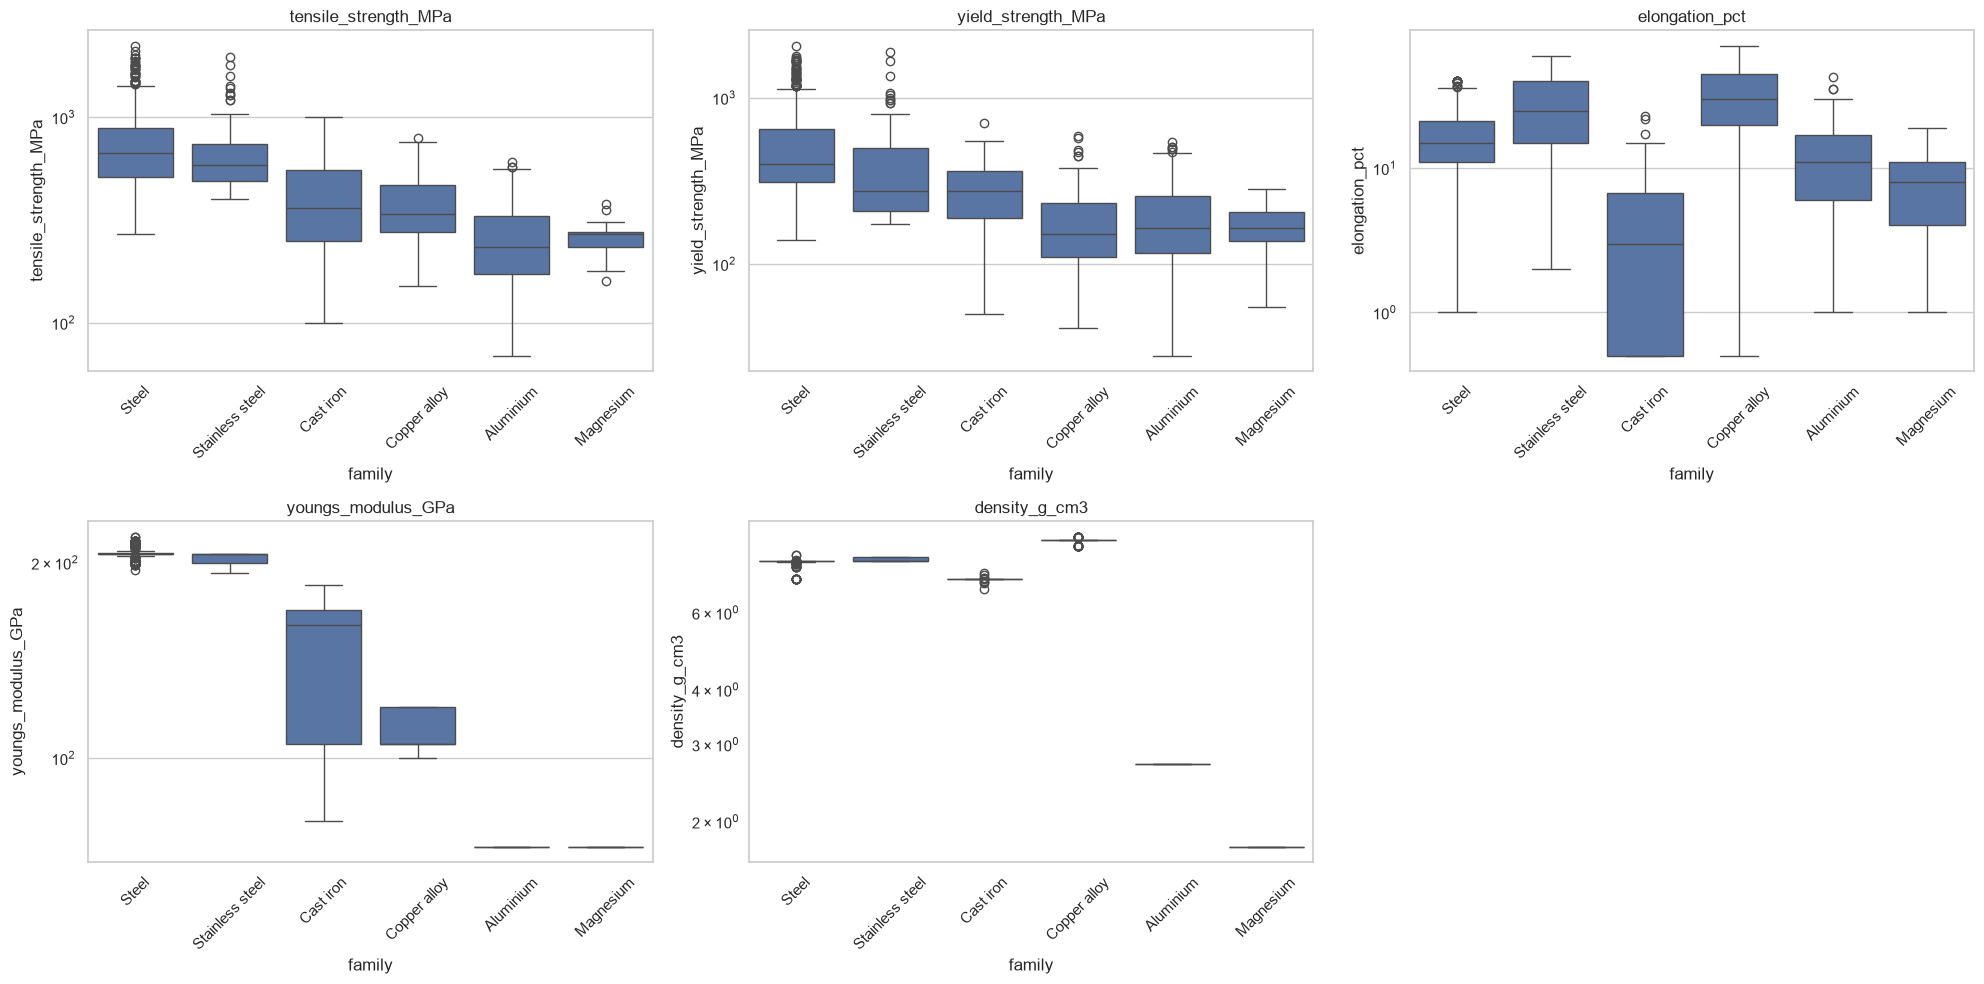

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, c in zip(axes.ravel(), CORE):
    sns.boxplot(data=df, x="family", y=c, ax=ax)
    ax.set_yscale("log"); ax.set_title(c)
    ax.tick_params(axis="x", rotation=45)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("../figures/03_boxplots_by_family.png", dpi=150); plt.show()

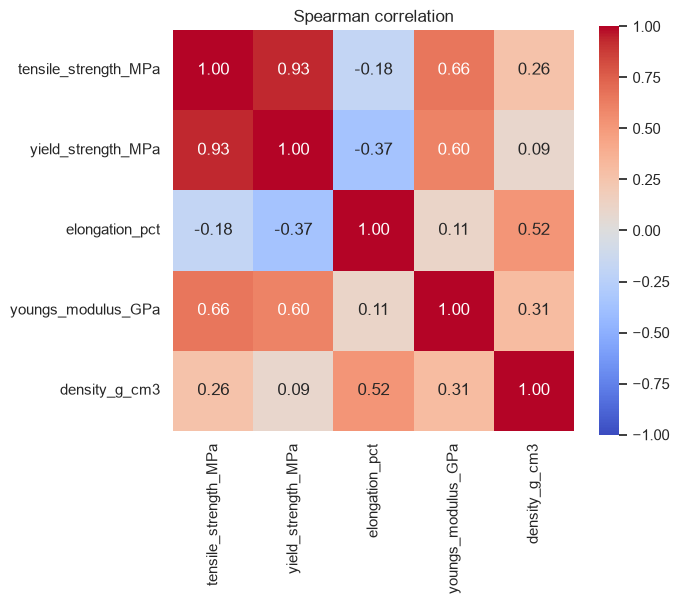

In [6]:
corr = df[CORE].corr(method="spearman")
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation")
plt.tight_layout(); plt.savefig("../figures/03_correlation.png", dpi=150); plt.show()

In [7]:
sus = df[(df["family"] == "Aluminium") & (df["density_g_cm3"] > 5)]
print(len(sus), "suspicious 'Aluminium' rows")
sus[["material", "standard", "density_g_cm3", "youngs_modulus_GPa"]].head(15)

0 suspicious 'Aluminium' rows


,material,standard,density_g_cm3,youngs_modulus_GPa


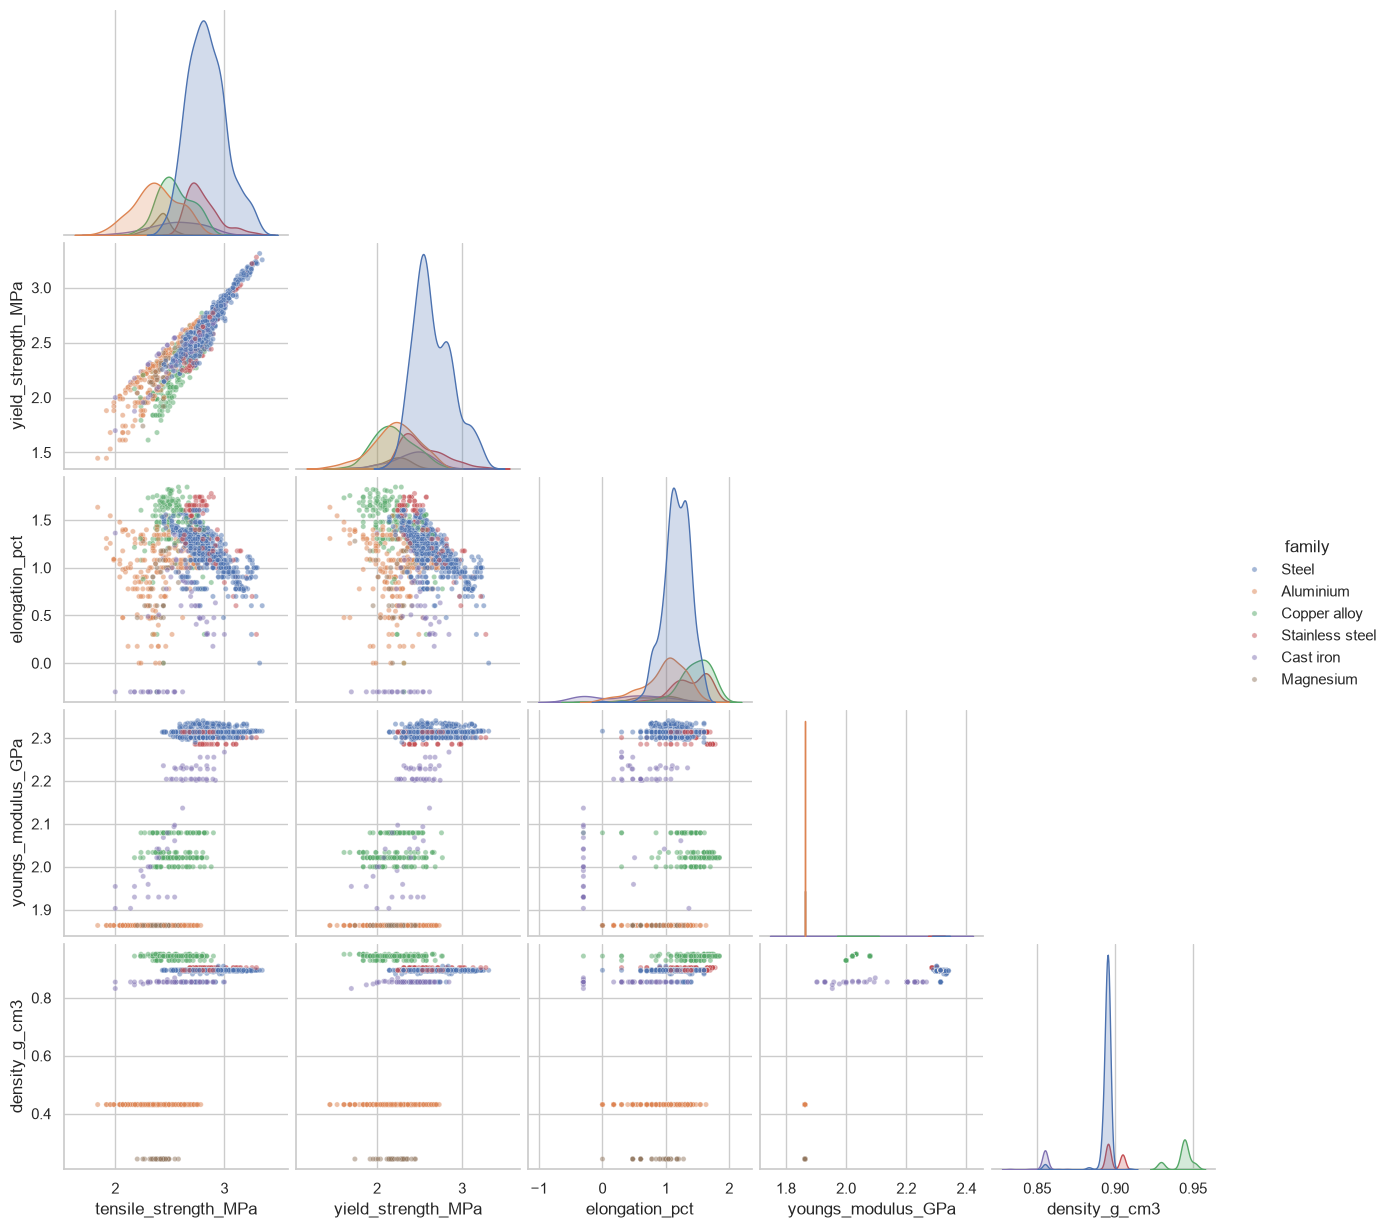

In [8]:
fam_order = df["family"].value_counts().index.tolist()

# Cell 6: pairplot on log10 values
plot_df = np.log10(df[CORE]).copy()
plot_df["family"] = df["family"]
g = sns.pairplot(plot_df, hue="family", hue_order=fam_order, corner=True,
                 plot_kws={"s": 14, "alpha": 0.5})
g.savefig("../figures/03_pairplot.png", dpi=120)

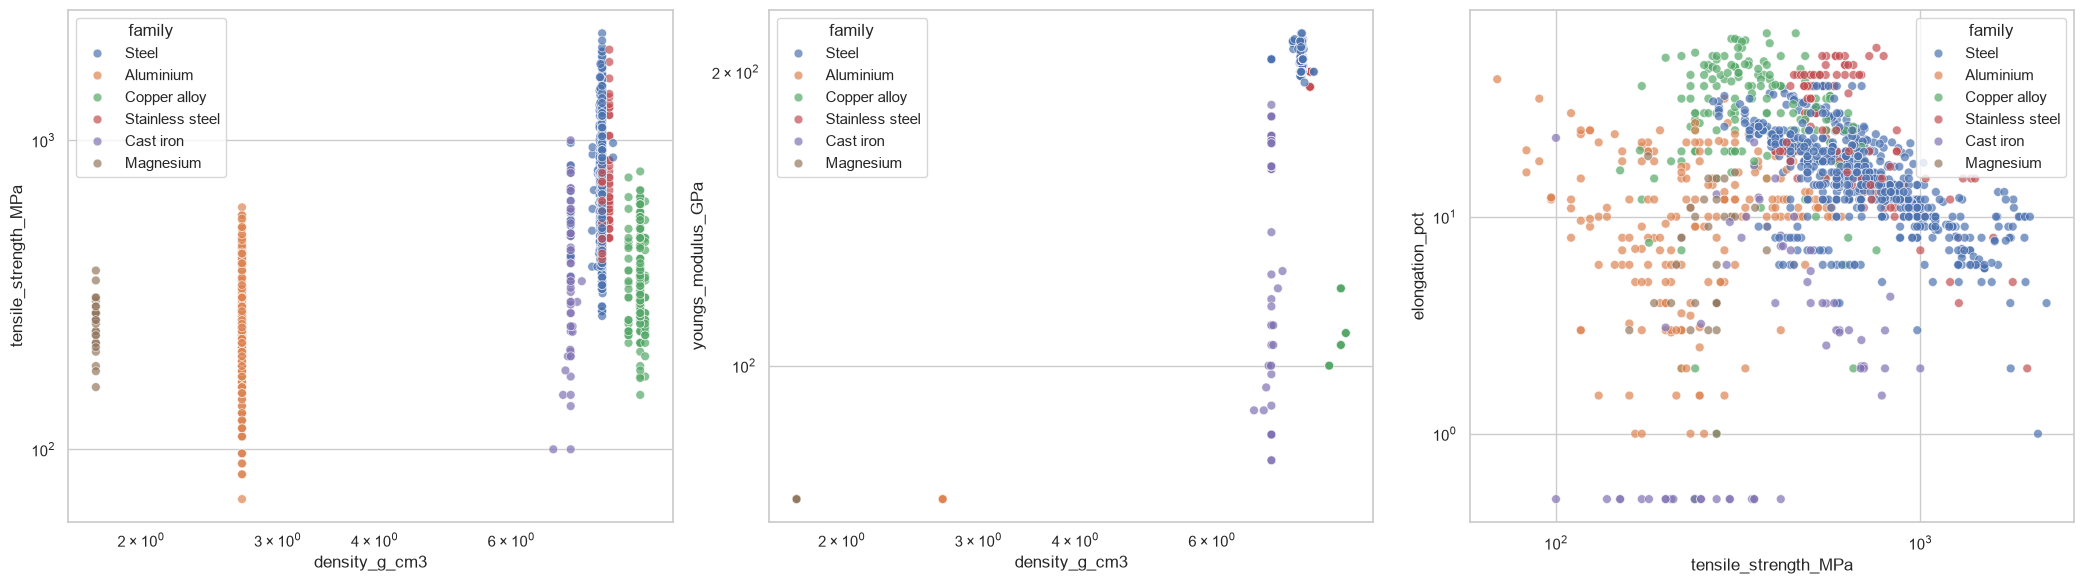

In [9]:
# Cell 7: Ashby-style charts
pairs = [("density_g_cm3", "tensile_strength_MPa"),
         ("density_g_cm3", "youngs_modulus_GPa"),
         ("tensile_strength_MPa", "elongation_pct")]
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=df, x=x, y=y, hue="family", hue_order=fam_order,
                    s=40, alpha=0.7, ax=ax)
    ax.set_xscale("log"); ax.set_yscale("log")
plt.tight_layout(); plt.savefig("../figures/03_ashby.png", dpi=150); plt.show()

# ## EDA findings

# **1. Family balance.** The dataset has 1,256 unique materials in six families: steel 684 (54.5%), aluminium 197 (15.7%), copper alloys 166 (13.2%), stainless steel 117 (9.3%), cast iron 62 (4.9%) and magnesium 30 (2.4%). Steel dominates and magnesium is small, so any cluster built mostly from magnesium should be interpreted cautiously.

# **2. Log transform.** Strengths are strongly right-skewed in raw units (tensile 1.43, yield 2.00). After a log10 transform they become nearly symmetric (-0.32 and -0.10). This suits materials data, where properties act multiplicatively. The transform does not help elongation (1.30 to -1.38), modulus (-0.77 to -0.90) or density (-1.56 to -1.71), because these are not smooth skewed distributions. Modulus and density are clumped into a few narrow values. We still apply the log to all five features for consistency.

# **3. Density and modulus act as family fingerprints.** Within a family they barely vary: steel is about 7.85 g/cm³ and 206 GPa, aluminium about 2.7 g/cm³, magnesium about 1.75 g/cm³, copper alloys about 8.8 g/cm³. They therefore mostly tell us which family a material belongs to, while tensile strength, yield strength and elongation are what differ within a family. Aluminium and magnesium share the same modulus in the source data, so modulus is a rough family-level value.

# **4. Tensile and yield strength are redundant.** Their Spearman correlation is 0.93 and they lie on a near-straight line on log-log axes. Strength therefore carries double weight in a 5-feature distance-based model, which we test later by dropping yield.

# **5. Strength-ductility trade-off.** In the strength vs elongation chart, steels form a clear downward diagonal: stronger steels are less ductile. Across all data this is only weakly visible (correlation of -0.18 with tensile, -0.37 with yield), because differences between families hide it. Copper alloys and stainless steels sit at high elongation, cast iron at the bottom. The positive elongation-density correlation (0.52) is a between-family effect (dense copper alloys are ductile, light Al and Mg alloys less so), not a physical law.

# **6. Assumption visible in the data.** The flat row of cast-iron points at 0.5% elongation is the 21 grey-iron values set by assumption (brittle material, elongation not reported). It appears as a left tail in the log-elongation histogram and is why elongation's skew gets worse after the log.